<h1 style="color:#A52A2A" >TP 2 : Apprentissage Profond avec TensorFlow / Keras </h1> 

<h2 style='color:#1E7FCB'>Exercice 1 : Reconnaissance de chiffres manuscrits (MNIST) </h2>

L’objectif est de construire un réseau de neurones entièrement connecté (Dense) avec <h8 color='#0000'>TensorFlow/Keras</h8> capable de reconnaître des chiffres manuscrits (0–9) à partir du jeu de données MNIST.

Les étapes à suivre : 
1. Charger et explorer les données 
2. Normaliser et visualiser les images
3. Créer et compiler un modèle de réseau de neurones 
4. L’entraîner et évaluer ses performances 5. Visualiser les courbes d’apprentissage et les prédictions 

<h5 style='color:#74D0F1'>1. Import des bibliothèques</h5>

In [2]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
print(f'Tensorflow version :',tf.__version__)

Tensorflow version : 2.22.0-rc0


<span style="color: blue;">1. Quelle est la différence entre TensorFlow et Keras ?</span>

-<h8 color='#0000'>TensorFlow</h8> est le moteur de bas niveau. C'est la bibliothèque principale qui gère les calculs mathématiques complexes, manipule les tenseurs et exploite la puissance des cartes graphiques (GPU) et des processeurs.

-<h8 color='#0000'>Keras</h8> est une interface de haut niveau (intégrée sous tf.keras). Elle a été conçue pour être simple et intuitive, permettant de construire, configurer et entraîner des réseaux de neurones en quelques lignes de code, sans avoir à manipuler la complexité mathématique brute de TensorFlow.

<span style="color: blue;">2. À quoi sert la couche Flatten dans un réseau de neurones ? </span>

La couche Flatten sert à aplatir des données multidimensionnelles (comme une image en 2D ) pour les transformer en un vecteur unidimensionnel.

<span style="color:red;">Pourquoi ?</span> Les couches de classification classiques (comme les couches denses) s'attendent à recevoir des listes de nombres à une seule dimension et non des matrices.

<span style="color: blue;">3. Quelle version de TensorFlow est installée sur votre machine ?</span>

Tensorflow version : 2.22.0-rc0

<span style="color: blue;">4. À quoi servent Sequential et Dense ? </span>

<h8 style='color:red;'>Sequential</h8> : C'est un conteneur qui permet de créer un modèle de réseau de neurones de manière linéaire. Il sert à "empiler" les couches les unes après les autres (les données traversent la première couche, puis la deuxième, etc.).

<h8 style='color:red;'>Dense</h8> : C'est une couche de neurones totalement connectée . Dans une couche Dense, chaque neurone est relié à tous les neurones de la couche précédente, ce qui lui permet d'analyser toutes les combinaisons de caractéristiques.

<h5 style='color:#74D0F1'>2. Chargement et préparation du dataset</h5> 

<h8 color='#0000'>Le dataset MNIST </h8>contient 70 000 images de chiffres manuscrits (28×28 pixels, niveaux de gris). 

In [5]:
(X_train,Y_train),(X_test,Y_test)=mnist.load_data()

In [6]:
# la Normalisation :

X_train=X_train/255.0
X_test=X_test/255.0

In [7]:
print(f'le X_train shape est :',X_train.shape)
print(f'le Y_train shape est :',Y_train.shape)

le X_train shape est : (60000, 28, 28)
le Y_train shape est : (60000,)


<span style='color:red'>Questions :</span> 

<span style="color: blue;">1. Pourquoi normalise-t-on les valeurs des pixels ?</span>

On normalise les valeurs des pixels ( pour les faire passer de l'intervalle [0, 255] à l'intervalle [0, 1]) principalement pour mettre toutes les données dans la même échelle.Cette mise à l'échelle uniforme apporte plusieurs avantages essentiels :

Équité entre les caractéristiques : Aucun pixel ou caractéristique n'a d'influence mathématique disproportionnée par rapport aux autres simplement à cause de valeurs numériques plus grandes.

Stabilité et rapidité : Elle permet aux algorithmes d'optimisation (comme la descente de gradient) de converger beaucoup plus rapidement et d'éviter les instabilités numériques lors des calculs.

<span style='color:red;'>la formule de la Normalisation </span>est : 

$$X_{norm} = \frac{X - X_{min}}{X_{max} - X_{min}}$$


<span style="color: blue;">2. Quelle est la taille d’une image et son type de données ? </span>

La forme (60000, 28, 28) signifie que notre jeu de données contient 60 000 images, et que chaque image a une taille de 28*28 pixels. 

Alors la taille d'une image est : 28*28 pixels.

Et son type de données est : 

-Brut (avant normalisation) : uint8 (des entiers de 0 à 255).

-Après normalisation : float32 ou float64 (des nombres décimaux de 0.0 à 1.0).

<span style="color: blue;">3. Combien d’exemples contient le jeu d’entraînement ?</span> 

Notre jeu de données contient 60 000 images.

<h5 style='color:#74D0F1'>3. Visualisation d’échantillons </h5>

Avant d’entraîner le modèle, observons quelques images pour vérifier que les données sont correctes.

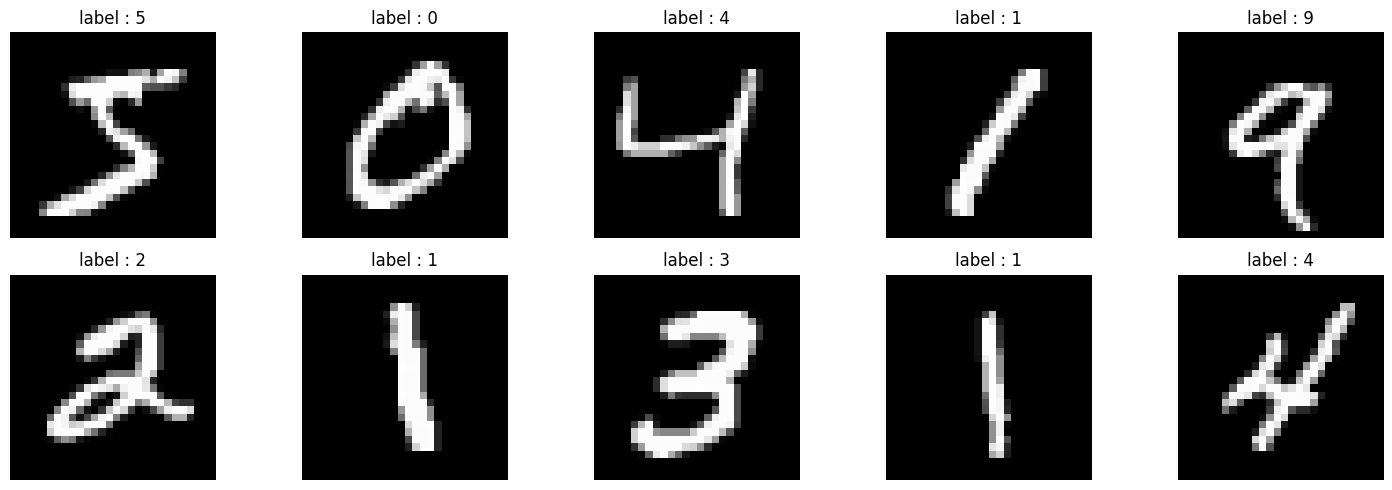

In [8]:
plt.figure(figsize=(15,5))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_train[i],cmap='gray')
    plt.title(f"label : {Y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()    

<span style='color:red'>Identification des chiffres :</span> Les images affichent bien les chiffres du jeu de données MNIST dans l'ordre (5, 0, 4, 1, 9, 2, 1, 3, 1, 4).  

<span style='color:red'>Vérification des labels :</span> Les étiquettes correspondent désormais exactement à chaque image correspondante (par exemple, le chiffre 5 a bien le label: 5, le chiffre 0 a le label: 0...).  

<span style='color:red'>Questions :</span>

<span style="color: blue;">1. Quelle commande permet de modifier le nombre d’images affichées ?</span>

C'est la boucle for i in range(10): (et plus particulièrement le nombre 10 dans le range) ainsi que les dimensions de la grille dans plt.subplot(2, 5, i+1) qui définissent le nombre d'images affichées.

<span style="color: blue;">2. Que représente l’argument cmap='gray' ?</span> 

L'argument cmap='gray' : indique à la fonction plt.imshow d'afficher l'image en niveaux de gris (du noir au blanc). Sans cet argument, Matplotlib appliquerait une palette de couleurs par défaut.

<span style="color: blue;">3. Quelle utilité a cette étape dans un projet d’IA ? </span>

Cette étape de visualisation des données a une utilité capitale dans un projet d'intelligence artificielle :

<span style='color:red'>Vérification de la qualité : </span>Elle permet de s'assurer que les données ont été correctement chargées et que les images ne sont pas corrompues ou illisibles.

<span style='color:red'>Alignement des labels :</span> Elle permet de vérifier que les étiquettes (labels) correspondent bien aux images affichées (pour éviter les erreurs de décalage ou de mauvaise correspondance entre les données et les cibles).

<span style='color:red'>Compréhension du problème : </span>Elle permet d'inspecter visuellement la complexité des données  avant de concevoir le réseau de neurones.

<h5 style='color:#74D0F1'>4. Construction du modèle de réseau de neurones</h5>

Le modèle Sequential est une pile linéaire de couches :
 1. Input(shape=(28,28)) → définit la taille de l’entrée 
 2. Flatten() → transforme chaque image 2D en vecteur 1D (784 valeurs) 
 3. Dense(128, activation='relu') → couche cachée avec 128 neurones 
 4. Dense(10, activation='softmax') → couche de sortie avec 10 classes (0–9) 

In [9]:
model=Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128,activation='relu'),
    Dense(10,activation='softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

<span style='color:red'>activation='relu' : </span>La fonction d'activation ReLU (Rectified Linear Unit) permet au modèle d'apprendre des relations complexes et non linéaires en remplaçant toutes les valeurs négatives par zéro.

<span style='color:red'>activation='softmax' : </span>Cette fonction transforme les scores bruts en probabilités (comprises entre 0 et 1, dont la somme totale fait 1). Le neurone qui obtient la probabilité la plus élevée indique le chiffre prédit par le modèle.

<span style='color:red'>Questions :</span>

<span style="color: blue;">1. Combien de paramètres le modèle contient-il ?</span>

Le modèle contient un total de 101 770 paramètres :

flatten : 0 paramètre   

dense : 100 480 paramètres 
  
dense_1 : 1 290 paramètres

<h7 color='#FF0000'>Explication :dense et meme chose pour dense_1</h7>

Poids= 784 * 128  = 100,352

Biais = 128 

Total = 100,352 + 128 = 100,480

<span style="color: blue;">2. Quelle est la fonction d’activation utilisée dans la couche de sortie ? Pourquoi ?</span> 

Fonction d'activation utilisée dans la couche de sortie : C'est la fonction softmax

<h7 style='color:#FF0000'>Pourquoi ?</h7>

Pour un problème de classification multiclasse : Le jeu de données MNIST comporte 10 classes possibles (les chiffres de 0 à 9). La fonction softmax est idéale car elle convertit les scores bruts (logits) de la dernière couche en un vecteur de probabilités comprises entre 0 et 1, dont la somme totale est exactement égale à 1.

Facilité de décision : Cela permet d'identifier facilement la prédiction du modèle en sélectionnant simplement la classe qui obtient la probabilité la plus élevée.

<span style="color: blue;">3. Quelle est la différence entre ReLU et Softmax ?</span>

ReLU : est utilisée principalement dans les couches cachées (intermédiaires) pour introduire de la non-linéarité et permettre au modèle d'apprendre des motifs complexes.

Softmax : est exclusivement utilisée dans la couche de sortie d'un modèle de classification multiclasse pour transformer les scores bruts en probabilités.

ReLU applique une opération simple : $f(x) = \max(0, x)$. Elle laisse passer les valeurs positives telles quelles et annule toutes les valeurs négatives.

Softmax prend en compte l'ensemble des scores de la couche de sortie pour calculer une distribution de probabilités normalisée (chaque sortie est comprise entre $0$ et $1$, et leur somme totale vaut $1$).

ReLU agit de manière indépendante sur chaque neurone, sans se soucier des autres neurones de la couche.

Softmax agit de manière globale : la valeur de chaque neurone de sortie dépend des scores de tous les autres neurones de cette même couche.


<span style="color: blue;">5. Compilation du modèle</span>

On définit :

• L’optimiseur (adam) : ajuste les poids pendant l’apprentissage 
 
• Loss function : calcule l’erreur entre la sortie et la vérité
 
• La métrique (accuracy) : évalue la précision du modèle 

In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

<span style="color: red;">Questions :</span> 

<span style="color: blue;">1. Qu’est-ce qu’un optimiseur ?</span>

Un optimiseur est un algorithme mathématique utilisé lors de l'entraînement d'un réseau de neurones pour ajuster les poids et les biais du modèle.

Son rôle principal est de minimiser l'erreur (loss function) en modifiant progressivement les paramètres du réseau, afin que ses prédictions deviennent de plus en plus précises.

<span style="color: blue;">2. Pourquoi utilise-t-on une fonction de perte ?  </span>

On utilise une fonction de perte (loss function) pour Mesurer l'erreur : Elle quantifie l'écart entre les prédictions du modèle et les vraies valeurs (les étiquettes réelles). Plus la valeur de la perte est élevée, plus le modèle se trompe.

<span style="color: blue;">3. Que se passe-t-il si on change la fonction de perte ?</span>

Changer de fonction de perte modifie la façon dont le modèle évalue ses erreurs ,les paramétres du modéle change . Si elle est inadaptée à votre tâche (comme utiliser une perte de régression pour de la classification), l'apprentissage échouera et le modèle fera de mauvaises prédictions.

<span style="color: blue;">4. Quelle serait la conséquence d’un mauvais choix d’optimiseur ?</span>


Un mauvais choix d'optimiseur peut entraîner un apprentissage extrêmement lent, bloquer le modèle dans une zone inefficace (minimum local ou point de selle), ou provoquer une divergence (l'erreur augmente au lieu de diminuer), rendant le modèle totalement incapable d'apprendre.

<span style="color: blue;">5. Quelle est la différence entre loss et metrics ? </span>

<span style='color:red'>La loss (Fonction de perte) :</span> C'est l'indicateur mathématique utilisé pendant l'entraînement. Elle guide directement l'optimiseur pour modifier les poids du modèle et minimiser l'erreur. (Le modèle cherche à la réduire au maximum).

<span style='color:red'>Les metrics (Métriques) :</span> Ce sont des indicateurs utilisés pour évaluer et interpréter les performances du modèle de façon compréhensible pour l'humain (comme l'exactitude ou accuracy). Elles ne sont pas utilisées par l'optimiseur pour ajuster les poids du réseau ; elles servent uniquement à la mesure et au suivi.

<h5 style='color:#74D0F1'>6. Entraînement du modèle</h5>

On entraîne le modèle sur les données d’entraînement pendant 5 époques. L’entraînement ajuste les poids pour minimiser la perte. 

In [11]:
history= model.fit(
    X_train,Y_train,
    epochs=5,
    batch_size=32,
    validation_data=(X_test,Y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9255 - loss: 0.2578 - val_accuracy: 0.9569 - val_loss: 0.1431
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9664 - loss: 0.1122 - val_accuracy: 0.9686 - val_loss: 0.1005
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9770 - loss: 0.0761 - val_accuracy: 0.9740 - val_loss: 0.0898
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9837 - loss: 0.0562 - val_accuracy: 0.9731 - val_loss: 0.0882
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9879 - loss: 0.0423 - val_accuracy: 0.9749 - val_loss: 0.0832


<span style='color:red'>La précision d’entraînement augmente-t-elle ? </span>

Oui, la précision d'entraînement (accuracy) augmente de manière constante et continue à chaque époque :

Époque 1 : $92,65\%$   

Époque 2 : $96,63\%$   

Époque 3 : $97,72\%$   

Époque 4 : $98,35\%$  

Époque 5 : $98,84\%$

<span style='color:red'>La précision de validation suit-elle la même tendance ? </span>

Oui, la précision de validation (val_accuracy) suit globalement la même tendance à la hausse, progressant fortement des époques 1 à 4, avant de se stabiliser ou de stagner très légèrement à l'époque 5 :

Époque 1 : $95,88\%$   

Époque 2 : $96,98\%$   

Époque 3 : $97,38\%$   

Époque 4 : $97,70\%$   

Époque 5 : $97,69\%$

<span style='color:red'>Questions:</span>

<span style='color:blue'>1. Que représente une “époque” ?</span>

Une époque (epoch) représente un passage complet de l'ensemble du jeu de données d'entraînement à travers le réseau de neurones.

<span style='color:blue'>2. Pourquoi utilise-t-on un jeu de validation ? </span>

On utilise un jeu de validation pour tester le modèle sur des données qu'il n'a jamais vues, afin de vérifier s'il généralise bien et d'éviter qu'il n'apprenne les exemples par cœur (overfitting).

<span style='color:blue'>3. Que se passerait-il si on augmentait le nombre d’époques à 50 ? </span>

Si on augmentait le nombre d'époques à 50, cela risquerait de provoquer du surapprentissage (overfitting) :

<span style='color:red'>Précision d'entraînement :</span> Elle continuerait d'augmenter pour s'approcher très près de $100\%$.

<span style='color:red'>Précision de validation :</span> Elle risquerait de stagner, voire de diminuer, car le modèle commencerait à mémoriser par cœur les détails des images d'entraînement au lieu d'apprendre à généraliser.

<h5 style='color:#74D0F1'>7. Évaluation du modèle</h5>

On teste le modèle sur des données jamais vues pendant l’entraînement. 

In [12]:
test_loss,test_accuracy=model.evaluate(X_test,Y_test)
print(f"le test loss est :{test_loss:.4f}")
print(f"le test accuracy est :{test_accuracy:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9749 - loss: 0.0832
le test loss est :0.0832
le test accuracy est :0.9749


<span style='color:red'>Questions :</span> 

<span style='color:blue'>1. Quelle est la précision finale de votre modèle ? </span>

D’après les résultats de l'évaluation sur le jeu de test affichés dans l'image, la précision finale (test accuracy) de votre modèle est de $0.9769$, soit environ $97,69\%$

<span style='color:blue'>2. Pourquoi la précision du test est souvent inférieure à celle d’entraînement ?</span>

La précision du test est souvent inférieure à celle d'entraînement parce que le modèle a été « optimisé » spécifiquement pour apprendre par cœur et réussir sur les exemples du jeu d'entraînement.

Lorsqu'il est confronté au jeu de test, il découvre de nouvelles données qu'il n'a jamais vues auparavant. Comme il doit généraliser ses connaissances plutôt que de réciter ce qu'il a mémorisé, ses performances baissent légèrement.

<span style='color:blue'>3. Que faire si le modèle surapprend (overfitting) ?</span>  

Pour lutter contre le surapprentissage :

<span style='color:red'>L'arrêt anticipé (Early Stopping) : </span>Arrêter l'entraînement dès que le modèle commence à moins bien performer sur les données de validation.

<span style='color:red'>Le Dropout : </span>Désactiver des neurones au hasard pendant l'apprentissage pour l'empêcher de tout mémoriser par cœur.

<span style='color:red'>Simplifier le modèle : </span>Réduire le nombre de couches ou de neurones.

<span style='color:red'>Ajouter plus de données :</span> Fournir un jeu de données d'entraînement plus grand et plus varié.

<h5 style='color:#74D0F1'>8. Visualisation des performances </h5>

Les courbes permettent de voir si le modèle apprend bien ou surapprend. 

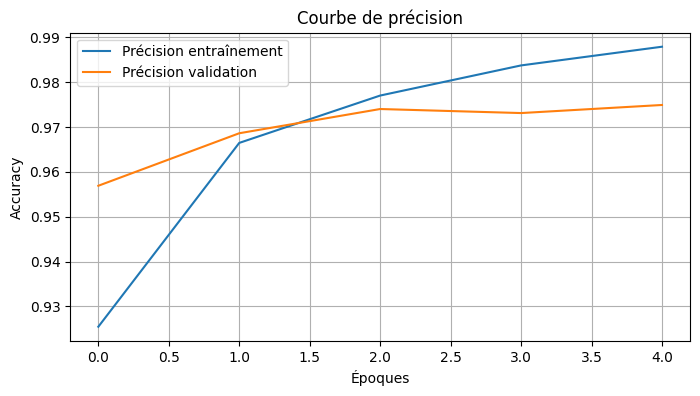

In [13]:
plt.figure(figsize=(8,4))
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

<span style='color:red'>Questions :</span> 

<span style='color:blue'>1. Que remarquez-vous sur les deux courbes ?</span>

La précision d'entraînement progresse continuellement pour s'approcher de $99\%$. 

La précision de validation augmente rapidement au début, puis se stabilise (plateau) autour de $97.5\%$ à partir de la deuxième époque, créant un écart visible avec la courbe d'entraînement. 

<span style='color:blue'>2. Comment détecter visuellement un surapprentissage ? </span>

On le repère lorsque les deux courbes se séparent nettement : la précision d'entraînement continue d'augmenter tandis que la précision de validation stagne ou commence à baisser.

<span style='color:blue'>3. Quelle stratégie pourrait-on utiliser pour y remédier ? </span>

Utiliser l'arrêt anticipé (Early Stopping) pour stopper l'entraînement dès que la validation stagne, ou ajouter du Dropout.

<span style='color:blue'>4. Que faire si les deux courbes divergent ? </span>

Réduire le nombre total d'époques (par exemple s'arrêter à 2 époques sur ce graphique) ou simplifier l'architecture du modèle pour l'empêcher de mémoriser les données par cœur.

<h5 style='color:#74D0F1'>9. Prédictions et visualisation</h5>

Nous affichons quelques images testées avec leur prédiction.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


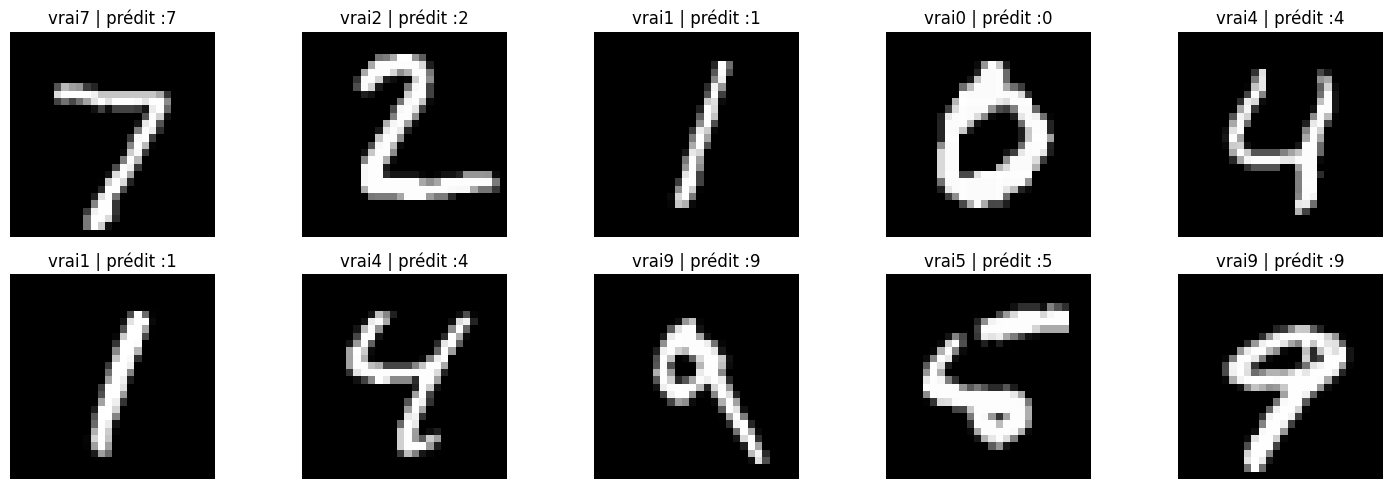

In [14]:
prediction=model.predict(X_test)

plt.figure(figsize=(15,5))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i],cmap='gray')
    plt.title(f"vrai{Y_test[i]} | prédit :{np.argmax(prediction[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()


<span style='color:red'>Questions :</span>

<span style='color:blue'>1. Le modèle fait-il des erreurs ? Sur quelles images ? </span>

Sur l'échantillon affiché dans cette image, le modèle ne fait aucune erreur : pour les 10 images présentées, le label réel (vrai) correspond exactement à ce que le modèle a deviné (prédit).  
 
(Cependant, de manière générale, avec une précision d'environ $97,69\%$, le modèle commet des erreurs sur d'autres images du jeu de test).

<span style='color:blue'>2. Comment expliquer une prédiction erronée ?</span>

Une erreur s'explique généralement par des ambiguïtés visuelles : des chiffres mal écrits, des traits inhabituels, ou des ressemblances fortes entre certaines classes (par exemple un 4 qui ressemble à un 9, ou un 7 confondu avec un 1). De plus, un réseau entièrement connecté (Dense) aplatit l'image et perd une partie de la structure spatiale des pixels.

<span style='color:blue'>3. Quelle technique permettrait d’améliorer la précision (ex : CNN) ? </span>

Utiliser un CNN (Réseau de neurones convolutifs) permettrait d'améliorer la précision. Contrairement aux réseaux denses, le CNN utilise des filtres pour analyser les formes locales, les contours et la structure spatiale 2D des images, ce qui est beaucoup plus performant pour la vision par ordinateur.

<h2 style='color:#1E7FCB'>Conclusion générale et analyse personnelle du travail</h2>

Au cours de ce travail pratique sur la classification des chiffres manuscrits de la base de données MNIST, nous avons parcouru l'ensemble de la chaîne de développement d'un modèle de Deep Learning :

<span style='color:blue'>1. Préparation des données et architecture</span>

<span style='color:red'>Normalisation :</span> Application de la mise à l'échelle Min-Max pour ramener les valeurs de pixels entre $0$ et $1$, facilitant la convergence de l'optimiseur.

<span style='color:red'>Fonctions d'activation :</span> Utilisation de ReLU dans les couches cachées pour introduire de la non-linéarité, et de Softmax dans la couche de sortie pour obtenir une distribution de probabilités sur les 10 classes.

<span style='color:blue'>2. Entraînement et dynamique d'apprentissage</span>

<span style='color:red'>Rôle des composantes :</span> Distinction essentielle entre la loss (qui guide l'optimiseur pour ajuster les poids) et les metrics (qui permettent à l'humain d'évaluer la performance).

<span style='color:red'>Suivi des époques :</span> L'entraînement sur 5 époques a montré une progression constante de la précision d'entraînement jusqu'à $98,84\%$, tandis que la précision de validation s'est stabilisée autour de $97,70\%$.  

<span style='color:blue'>3. Évaluation finale et diagnostic</span>

<span style='color:red'>Performances :</span> Le modèle atteint une précision finale globale sur le jeu de test de $97,69\%$.  

<span style='color:red'>Analyse des courbes :</span> Le léger écart entre l'entraînement et la validation illustre l'amorce du surapprentissage (overfitting)

<span style='color:blue'>4. Perspectives d'amélioration</span>

Pour aller plus loin et dépasser les limites d'un réseau dense classique :

<span style='color:red'>Régularisation :</span> Intégrer du Dropout ou de l'Early Stopping pour éviter la mémorisation par cœur.

<span style='color:red'>Changement d'architecture :</span> Passer à un réseau de neurones convolutifs (CNN), plus adapté au traitement d'images grâce à sa capacité à préserver les relations spatiales entre les pixels.

<h2 style='color:#1E7FCB'>Exercice 2 : classification d’images en utilisant le dataset FashionMNIST</h2> 

Objectif : Découvrir et expérimenter les principes du Deep Learning à travers la classification d’images en utilisant le dataset Fashion-MNIST.

• Construire un réseau de neurones artificiels (ANN) puis un réseau convolutif (CNN). 

• Analyser les résultats à l’aide de métriques et de courbes. 

• Comprendre le rôle des fonctions d’activation et expérimenter leurs effets.

<span style='color:blue'>Jeu de données : Fashion-MNIST : </span>

![Fashion-MNIST](Fashion-MNIST.png)

• 70 000 images (60 000 pour l’entraînement, 10 000 pour le test) 

• Chaque image : 28 × 28 pixels, niveaux de gris 

• 10 classes de vêtements (T-shirt, pantalon, pull, robe, manteau, sandale, chemise, basket, sac, bottine) 

<span style='color:blue'>Chargement via Keras :</span>

In [15]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns


In [16]:
# Pour la reproductibilité :
tf.random.set_seed(42)

In [17]:
# Chargement du Dataset :
(x_train,y_train),(x_test,y_test)=fashion_mnist.load_data()

<h5 style='color:#74D0F1'>Étape 1 – Exploration du jeu de données</h5> 

<span style='color:blue'>A. Dimensions et types </span>

In [18]:
print(f"la dimension du Train :",x_train.shape)
print(f"la dimension du test :",x_test.shape)

la dimension du Train : (60000, 28, 28)
la dimension du test : (10000, 28, 28)


<span style='color:blue'>B. Visualisation d’exemples </span>

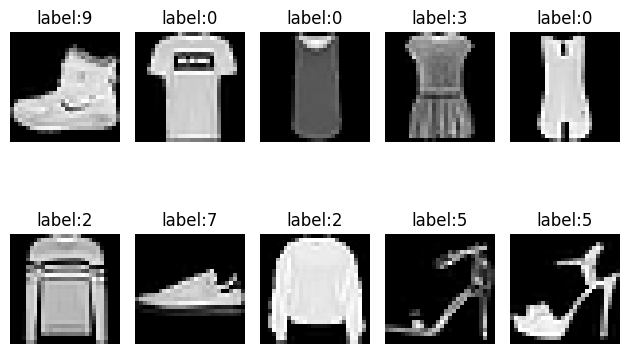

In [19]:
plt.Figure(figsize=(15,5))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i],cmap='gray')
    plt.title(f'label:{y_train[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()    

Chaque nombre correspond à une catégorie de vêtement précise :

0 : T-shirt / haut (T-shirt/top)

1 : Pantalon (Trouser)

2 : Pull (Pullover)

3 : Robe (Dress)

4 : Manteau (Coat)

5 : Sandale (Sandal)

6 : Chemise (Shirt)

7 : Basket (Sneaker)

8 : Sac (Bag)

9 : Bottine (Ankle boot)

<span style='color:red'>Question :</span>

<span style='color:blue'>Que remarquez-vous sur la nature des données et la taille des images ? </span>

Dans la base de données Fashion-MNIST (comme dans MNIST), les données $Y$ (que l'on appelle souvent les étiquettes ou labels) sont des nombres entiers allant de $0$ à $9$.
Aussi la taile est 28*28.

<h5 style='color:#74D0F1'>Étape 2 – Prétraitement des données</h5>

• Mise à l’échelle des pixels entre 0 et 1 

• Conversion en float 

• Encodage des labels

In [20]:
from tensorflow.keras.utils import to_categorical

# La normalisation entre 0 et 1 :
x_train=x_train.astype('float32')/255.0
x_test=x_test.astype('float32')/255.0

# Encodage en hot des labels : 
y_train_cat=to_categorical(y_train,10)
y_test_cat=to_categorical(y_test,10)

<span style='color:red'>Questions : </span>

<span style='color:blue'>1. Pourquoi faut-il normaliser les images ?</span>

Il faut normaliser les images pour les raisons suivantes :

<span style='color:red'>Accélération de la convergence : </span>Des valeurs d'entrée plus petites et centrées permettent aux gradients de se propager plus efficacement, ce qui aide l'optimiseur à trouver plus rapidement les bons poids.

<span style='color:red'>Stabilité numérique : </span>Cela évite que de grandes valeurs de pixels ne s'accumulent et provoquent des erreurs de calcul (valeurs trop grandes ou instables) dans les couches du réseau de neurones.


<span style='color:blue'>2. Quelle est l’importance du one-hot encoding dans un problème de classification multiclasse ?</span>

Pour transformer les étiquettes en vecteurs (par exemple [0, 0, 1, 0...]) afin de les comparer directement aux 10 probabilités de sortie du modèle, et pour éviter de donner un faux ordre mathématique entre les catégories.

<h5 style='color:#74D0F1'>Étape 3 – Création d’un modèle dense (ANN)</h5>

<span style='color:blue'>Création du modèle de base : </span>

In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,Flatten,Dropout

model=Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128,activation='relu'),
    Dropout(0.2),
    Dense(64,activation='relu'),
    Dense(10,activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

<span style='color:blue'>Compilation et entraînement </span>

In [22]:
# Compilation :
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [23]:
# Entarainement :
history=model.fit(
    x_train,y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7818 - loss: 0.6276 - val_accuracy: 0.8502 - val_loss: 0.4285
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8463 - loss: 0.4290 - val_accuracy: 0.8594 - val_loss: 0.4009
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8603 - loss: 0.3896 - val_accuracy: 0.8656 - val_loss: 0.3787
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8679 - loss: 0.3615 - val_accuracy: 0.8707 - val_loss: 0.3686
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8750 - loss: 0.3441 - val_accuracy: 0.8720 - val_loss: 0.3589
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8780 - loss: 0.3311 - val_accuracy: 0.8765 - val_loss: 0.3436
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8832 - loss: 0.3155 - val_accuracy: 0.8770 - val_loss: 0.3459
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8864 - loss: 0.3088 - val_accuracy: 0.

<span style='color:blue'>Visualisation </span>

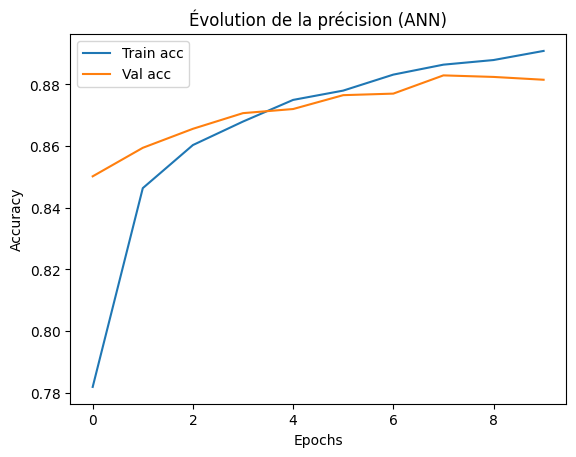

In [24]:
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

<span style='color:red'>Questions :</span>

<span style='color:blue'>1. Pourquoi utilise-t-on la fonction d’activation ReLU ici ?</span>

Pour introduire de la non-linéarité dans le réseau de neurones, ce qui lui permet d'apprendre des motifs complexes, tout en étant rapide à calculer et en évitant les problèmes de blocage des gradients.

<span style='color:blue'>2. Quelle est la différence entre accuracy et val_accuracy ? </span>

<span style='color:red'>accuracy</span> mesure la précision du modèle sur les données d'entraînement (ce qu'il apprend).

<span style='color:red'>val_accuracy</span> mesure sa précision sur les données de validation (des images qu'il n'a jamais vues pendant l'apprentissage, pour tester sa capacité de généralisation).

<span style='color:blue'>3. Que se passe-t-il si l’on augmente le nombre d’époques à 50 ? </span>

Le modèle risque de faire du surapprentissage (overfitting) : il va commencer à apprendre par cœur les détails du jeu d'entraînement, ce qui fera continuer d'augmenter la précision d'entraînement tandis que la précision de validation stagnera ou commencera à baisser.

<span style='color:blue'>Évaluation finale :</span>

In [25]:
test_loss,test_acc=model.evaluate(x_test,y_test_cat)
print(f"la Précision sur le test est :",test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8771 - loss: 0.3474
la Précision sur le test est : 0.8770999908447266


<h5 style='color:#74D0F1'>Étape 4 — Introduction aux Fonctions d’Activation</h5>

Comparer les performances des fonctions : sigmoïde, tanh, ReLU, et LeakyReLU.

In [26]:
from tensorflow.keras.layers import LeakyReLU

activations=['sigmoid','tanh','relu']
results={}

for act in activations:
    model_act=Sequential([
        Input(shape=(28,28)),
        Flatten(),
        Dense(128,activation=act),
        Dense(64,activation=act),
        Dense(10,activation='softmax')
    ])

model_act.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)    

h=model_act.fit(x_train,y_train_cat,epochs=5,batch_size=128,validation_split=0.2,verbose=0)
results[act] = h.history['val_accuracy'][-1]

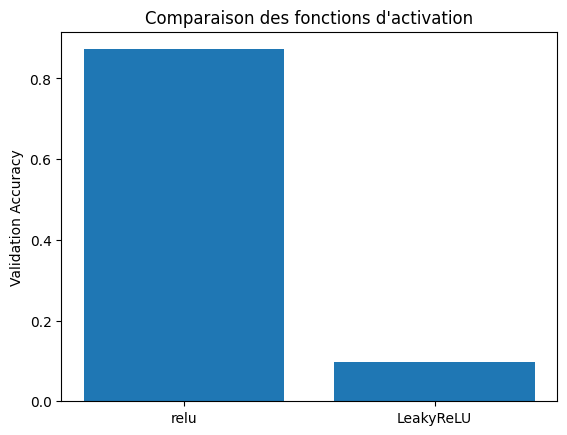

In [27]:
# Leaky ReLU
model_leaky = Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]

plt.bar(results.keys(), results.values())
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.show()

<span style='color:red'>Questions :</span> 

<span style='color:blue'>1. Quelle fonction d’activation donne les meilleurs résultats ?</span> 

D'après le graphique de comparaison fourni, c'est relu qui donne les meilleurs résultats avec une précision de validation (Validation Accuracy) élevée (proche de $0,87$), surpassant nettement LeakyReLU dans ce cas de figure. 

<span style='color:blue'>2. Pourquoi les fonctions sigmoïde et tanh sont moins utilisées dans les couches cachées ?</span>

<span style='color:red'>Le problème du gradient qui disparaît : </span>Leurs dérivées deviennent extrêmement faibles (proches de 0) pour les grandes valeurs positives ou négatives. Lors de la rétropropagation (backpropagation), ces gradients quasi-nuls empêchent les poids des couches profondes de se mettre à jour efficacement.

<span style='color:red'>La saturation :</span> Leurs courbes s'aplatissent aux extrémités (entre 0 et 1 pour la sigmoïde, entre -1 et 1 pour tanh), ce qui fait perdre de l'information sur l'amplitude des signaux.

<span style='color:red'>Le manque de centrage sur zéro (pour la sigmoïde) :</span> Ses sorties sont toujours positives, ce qui peut provoquer des oscillations inefficaces lors de la descente de gradient.

<span style='color:blue'>3. À quoi sert LeakyReLU ? </span>

LeakyReLU (Leaky Rectified Linear Unit) sert à résoudre le problème du « neurone mort » 

(dying ReLU) :Avec une fonction relu classique, si un neurone reçoit une entrée négative, sa sortie devient $0$ et son gradient devient nul. Le neurone se « désactive » définitivement et ne participe plus à l'apprentissage.


LeakyReLU corrige cela en introduisant une petite pente constante pour les valeurs négatives (par exemple, $0.1 \times x$). Cela permet de maintenir un gradient non nul, garantissant que le neurone continue d'apprendre même s'il est traversé par des valeurs négatives.

<h5 style='color:#74D0F1'>Étape 5 : Modèle CNN (Convolutional Neural Network)</h5>

<span style='color:blue'>Création du modèle CNN</span>

In [28]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Reshape pour ajouter la dimension "canal"
X_train_cnn = x_train.reshape(-1, 28, 28, 1)
X_test_cnn = x_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

<span style='color:blue'>Entraînement </span>

In [29]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.7629 - loss: 0.6544 - val_accuracy: 0.8410 - val_loss: 0.4276
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.8518 - loss: 0.4104 - val_accuracy: 0.8697 - val_loss: 0.3485
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.8740 - loss: 0.3528 - val_accuracy: 0.8812 - val_loss: 0.3174
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.8850 - loss: 0.3188 - val_accuracy: 0.8907 - val_loss: 0.2998
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8918 - loss: 0.2969 - val_accuracy: 0.8935 - val_loss: 0.2921
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.8979 - loss: 0.2791 - val_accuracy: 0.8968 - val_loss: 0.2803
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9053 - loss: 0.2610 - val_accuracy: 0.8984 - val_loss: 0.2747
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9104 - loss: 0.2481 - val_acc

<span style='color:blue'>Évaluation</span>

In [30]:
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9056 - loss: 0.2638
Précision CNN sur test set : 0.9056000113487244


<span style='color:red'>Questions : </span>

<span style='color:blue'>1. Quelle est la différence entre un ANN et un CNN ? </span>

<span style='color:red'>ANN (Artificial Neural Network / Réseau de neurones artificiels) :</span> Il est constitué de couches entièrement connectées (Fully Connected). Chaque neurone d'une couche est connecté à tous les neurones de la couche précédente. Cela nécessite de "aplatir" (flatten) les images en un vecteur unidimensionnel, ce qui détruit la structure spatiale 2D des pixels.

<span style='color:red'>CNN (Convolutional Neural Network / Réseau de neurones convolutionnels) : </span>Il utilise des couches de convolution et de pooling. Il préserve la structure spatiale 2D de l'image en appliquant des filtres locaux qui parcourent l'image pour extraire des caractéristiques visuelles (bords, textures, formes).

<span style='color:blue'>2. Pourquoi le CNN donne-t-il généralement de meilleurs résultats ?</span>

<span style='color:red'>Conservation de la structure spatiale :</span> Contrairement à l'ANN, le CNN analyse l'image en tenant compte des relations de voisinage entre les pixels grâce aux filtres de convolution.

<span style='color:red'>Partage des poids :</span> Un même filtre  est appliqué sur toute l'image, ce qui réduit considérablement le nombre de paramètres à apprendre par rapport à un ANN et évite le surapprentissage (overfitting).

<span style='color:red'>Invariance par translation :</span> Grâce aux couches de pooling et de convolution, le CNN est capable de détecter un motif ou un objet peu importe où il se situe dans l'image.

<span style='color:blue'>3. Quel est le rôle des couches de Pooling ? </span>

<span style='color:red'>Réduction de la dimensionnalité :</span> Elles réduisent la taille spatiale (hauteur et largeur) des cartes de caractéristiques, ce qui diminue le nombre de paramètres et le coût de calcul pour les couches suivantes.

<span style='color:red'>Invariance aux petites variations :</span> En conservant par exemple uniquement la valeur maximale (Max Pooling) dans une région, elles rendent la détection des caractéristiques plus robuste face aux légers déplacements, rotations ou distorsions de l'image.

<h5 style='color:#74D0F1'>Étape 6 — Visualisation des performances

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


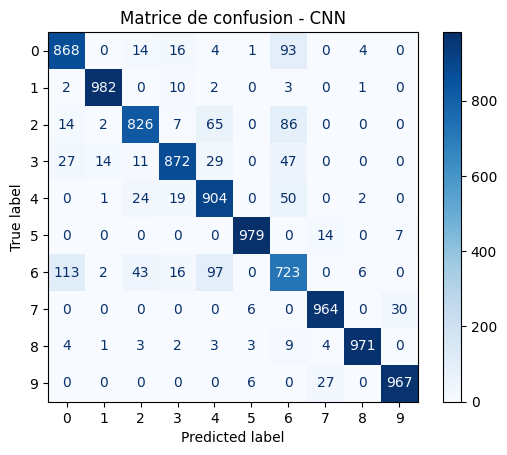

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matrice de confusion - CNN")
plt.show()

<span style='color:red'>Questions :</span>

<span style='color:blue'>1. Quelles classes sont le plus souvent confondues ?</span> 

La confusion la plus importante a lieu entre la classe 6 (vraie étiquette) et la classe 0 (étiquette prédite), avec 113 erreurs.   

On observe également de fortes confusions entre la classe 6 et la classe 4 (97 erreurs), ainsi qu'entre la classe 0 et la classe 6 (93 erreurs) et entre la classe 2 et la classe 6 (86 erreurs).  

<span style='color:blue'>2. Comment peut-on réduire ces erreurs de classification ? </span>

Pour réduire ces erreurs et améliorer les performances du modèle, on peux :

<span style='color:red'>Appliquer l'augmentation de données (Data Augmentation) :</span> Introduire des variations (rotations, translations, zooms) pour aider le modèle à mieux généraliser les formes similaires.

<span style='color:red'>Ajuster l'architecture du modèle : </span>Modifier le nombre de filtres de convolution, la taille des noyaux ou ajouter des couches pour capturer des caractéristiques plus discriminantes.

<span style='color:red'>Optimiser les hyperparamètres :</span> Ajuster le taux d'apprentissage (learning rate), le nombre d'époques (epochs), ou affiner les couches de régularisation (comme le Dropout).

<h5 style='color:#74D0F1'>Étape 7 : Data Augmentation</h5> 

In [32]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train_cnn)

cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.8623 - loss: 0.3840 - val_accuracy: 0.8943 - val_loss: 0.2899
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.8806 - loss: 0.3264 - val_accuracy: 0.8978 - val_loss: 0.2733
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.8858 - loss: 0.3131 - val_accuracy: 0.8991 - val_loss: 0.2699
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.8905 - loss: 0.2992 - val_accuracy: 0.9027 - val_loss: 0.2630
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.8931 - loss: 0.2908 - val_accuracy: 0.8964 - val_loss: 0.2813
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.8964 - loss: 0.2817 - val_accuracy: 0.8982 - val_loss: 0.2765
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.8975 - loss: 0.2767 - val_accuracy: 0.9103 - val_loss: 0.2501
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.9001 - loss: 0.2713 - 

<span style='color:red'>Questions :</span> 

<span style='color:blue'>1. Quel est l’intérêt de la Data Augmentation ? </span>

<span style='color:red'>Amélioration de la généralisation :</span> Elle permet d'augmenter artificiellement la taille du jeu de données d'entraînement en générant de nouvelles variations des images existantes . Cela aide le modèle à mieux reconnaître les objets dans des conditions variées et à éviter le surapprentissage (overfitting). 

<span style='color:red'>Robustesse accrue : </span>Le modèle devient moins sensible aux variations de position, d'orientation ou d'échelle des objets présents sur les images.

<span style='color:blue'>2. Quels types de transformations semblent les plus efficaces pour ce dataset ? </span>

Les légères rotations (rotation_range=10) et les zooms modérés (zoom_range=0.1) sont particulièrement efficaces car ils reproduisent les imperfections naturelles de l'écriture manuscrite ou du cadrage.

<h5 style='color:#74D0F1'>Conclusion : </h5>

Cet exercice nous a permis d'explorer et d'analyser le cycle complet de conception d'un modèle de Deep Learning pour la classification d'images :


<span style='color:red'>Choix de l'architecture :</span> L'utilisation des réseaux de neurones convolutionnels (CNN) s'est révélée nettement plus performante qu'un réseau de neurones standard (ANN), grâce à la conservation de la structure 2D des images et à l'extraction efficace des caractéristiques visuelles par les couches de convolution et de pooling.


<span style='color:red'>Choix des fonctions d'activation : </span>Les expérimentations ont montré la supériorité de la fonction ReLU dans les couches cachées par rapport aux fonctions classiques (Sigmoïde et Tanh), en évitant le problème du gradient qui disparaît (vanishing gradient).


<span style='color:red'>Analyse des erreurs :</span> La matrice de confusion a permis d'identifier précisément les classes les plus fréquemment confondues par le modèle (principalement les classes $6$, $0$ et $4$).  


<span style='color:red'>Amélioration par Data Augmentation :</span> Pour pallier ces confusions et éviter le surapprentissage, la mise en place de la Data Augmentation (rotation_range, zoom_range, horizontal_flip) permet de diversifier les données d'entraînement et d'améliorer la capacité de généralisation du réseau.